- DSC540-T303 Data Preparation  
- Term Project, Final Milestone  
- Shelia Howard

## Term Project Milestone 5: Merging, Storing, and Visualizing County-Level Healthcare Data

### Introduction

This notebook completes the final DSC540 term project milestone by loading three cleaned healthcare-related datasets into a SQLite database, storing each source as an individual table, joining the tables together through SQL, and creating five visualizations from the prepared data. For this final milestone, the notebook uses cleaned county-level records carried forward from the prior milestones so the database, SQL join, and visualization workflow can be demonstrated in one reproducible notebook.

The project topic is **county-level healthcare utilization and drivers of high-cost care**. The analysis connects three sources identified across the prior milestones:

1. **CMS-style utilization data** representing emergency department visits, inpatient admissions, and population.
2. **CDC chronic disease data** representing county-level prevalence indicators such as diabetes, obesity, high blood pressure, coronary heart disease, and stroke.
3. **Hospital infrastructure data** representing hospital count, staffed beds, ownership type, and location classification.

The main goal is to demonstrate how cleaned datasets can be loaded into a relational database, joined by a shared county FIPS identifier, and visualized to support exploratory analysis. Throughout the notebook, each code block includes comments explaining what the code is doing and why the step matters. 

The notebook contains the following major sections:

1. Import required Python libraries.
2. Create cleaned source datasets based on prior milestone outputs.
3. Load each dataset into SQLite as an individual table.
4. Join the datasets using SQL joins.
5. Validate the joined dataset.
6. Create five clearly labeled visualizations.
7. Print the final human-readable dataset.
8. Provide a 250-500 word summary and ethical implications discussion.
9. Conclude with connections to course concepts from the week.

In [1]:
# Import sqlite3 so the notebook can create and work with a local SQLite database.
import sqlite3

# Import Path so file paths can be created in a clear and operating-system-friendly way.
from pathlib import Path

# Import pandas so tabular data can be created, loaded, joined, queried, and displayed.
import pandas as pd

# Import numpy so numeric calculations and conditional fields can be created cleanly.
import numpy as np

# Import matplotlib.pyplot so the notebook can create required visualizations.
import matplotlib.pyplot as plt

# Import display so DataFrames can be shown in a readable notebook format.
from IPython.display import display

# Set pandas to show more columns so the merged healthcare dataset is easier to review.
pd.set_option("display.max_columns", 50)

# Set the pandas display width so wide tables wrap less in the notebook output.
pd.set_option("display.width", 140)

# Set the default figure size so charts export more clearly to PDF.
plt.rcParams["figure.figsize"] = (10, 6)
# This setting helps charts display consistently in both the notebook and exported PDF.

### Why this code block matters

This block prepares the Python environment for the final milestone. SQLite is used because it is a free relational database option and fits the assignment requirement to store the cleaned datasets in a database. pandas supports DataFrame creation and SQL query results, while Matplotlib supports the required visualizations. The display settings make the notebook easier to read when exported to PDF.

## Create Cleaned Dataset #1: County Healthcare Utilization Table

This section recreates the cleaned utilization table structure from the prior flat-file milestone. The records are defined directly in this final notebook to keep the database workflow reproducible, but the fields reflect the cleaned utilization data prepared earlier in the project.

In [2]:
# Create a list of dictionaries containing cleaned county-level utilization records.
utilization_records = [
    # Store Davidson County utilization values.
    {"county_fips": "47037", "state_abbr": "TN", "county_name": "Davidson County", "cms_ed_visits": 182500, "cms_inpatient_admissions": 41200, "population": 715884},
    # Store Rutherford County utilization values.
    {"county_fips": "47149", "state_abbr": "TN", "county_name": "Rutherford County", "cms_ed_visits": 96000, "cms_inpatient_admissions": 18900, "population": 367101},
    # Store Shelby County utilization values.
    {"county_fips": "47157", "state_abbr": "TN", "county_name": "Shelby County", "cms_ed_visits": 375000, "cms_inpatient_admissions": 68400, "population": 916371},
    # Store Knox County utilization values.
    {"county_fips": "47093", "state_abbr": "TN", "county_name": "Knox County", "cms_ed_visits": 128700, "cms_inpatient_admissions": 35525, "population": 500669},
    # Store Hamilton County utilization values.
    {"county_fips": "47065", "state_abbr": "TN", "county_name": "Hamilton County", "cms_ed_visits": 118450, "cms_inpatient_admissions": 29850, "population": 374682},
]

# Convert the list of utilization records into a pandas DataFrame.
utilization_df = pd.DataFrame(utilization_records)

# Standardize the county FIPS field as a five-character text identifier.
utilization_df["county_fips"] = utilization_df["county_fips"].astype(str).str.zfill(5)

# Calculate emergency department visits per 1,000 residents for fair county comparison.
utilization_df["ed_visits_per_1000"] = (utilization_df["cms_ed_visits"] / utilization_df["population"]) * 1000

# Calculate inpatient admissions per 1,000 residents for fair county comparison.
utilization_df["inpatient_admissions_per_1000"] = (utilization_df["cms_inpatient_admissions"] / utilization_df["population"]) * 1000

# Calculate the 75th percentile of emergency department visit rates for a high-utilization rule.
ed_rate_75th = utilization_df["ed_visits_per_1000"].quantile(0.75)

# Calculate the 75th percentile of inpatient admission rates for a high-utilization rule.
inpatient_rate_75th = utilization_df["inpatient_admissions_per_1000"].quantile(0.75)

# Create a high-utilization flag when either utilization rate is at or above the 75th percentile.
utilization_df["high_utilization_region"] = np.where(
    (utilization_df["ed_visits_per_1000"] >= ed_rate_75th) | (utilization_df["inpatient_admissions_per_1000"] >= inpatient_rate_75th),
    "Yes",
    "No",
)

# Round rate fields to two decimals so the table is easier to read.
utilization_df[["ed_visits_per_1000", "inpatient_admissions_per_1000"]] = utilization_df[["ed_visits_per_1000", "inpatient_admissions_per_1000"]].round(2)

# Display the cleaned utilization table before it is loaded into SQLite.
display(utilization_df)

,county_fips,state_abbr,county_name,cms_ed_visits,cms_inpatient_admissions,population,ed_visits_per_1000,inpatient_admissions_per_1000,high_utilization_region
0,47037,TN,Davidson County,182500,41200,715884,254.93,57.55,No
1,47149,TN,Rutherford County,96000,18900,367101,261.51,51.48,No
2,47157,TN,Shelby County,375000,68400,916371,409.22,74.64,Yes
3,47093,TN,Knox County,128700,35525,500669,257.06,70.96,No
4,47065,TN,Hamilton County,118450,29850,374682,316.13,79.67,Yes


### Why this code block matters

This block creates the first database-ready source table. The utilization table preserves county FIPS as the join key, keeps raw utilization counts, and creates rate-based fields so counties with different population sizes can be compared more fairly. The high-utilization flag supports the project’s larger question about where potentially high-cost care patterns may be occurring.

## Create Cleaned Dataset #2: CDC Chronic Disease Table

This section creates the cleaned chronic disease table based on the CDC PLACES API structure used in Milestone 4. The table is limited to the Tennessee counties used in the final joined analysis so it aligns with the utilization and hospital infrastructure tables.

In [3]:
# Create a list of dictionaries containing cleaned county-level chronic disease records.
chronic_records = [
    # Store Davidson County chronic disease values.
    {"county_fips": "47037", "diabetes_percent": 12.6, "obesity_percent": 32.4, "high_blood_pressure_percent": 36.8, "coronary_heart_disease_percent": 5.6, "stroke_percent": 3.1},
    # Store Rutherford County chronic disease values.
    {"county_fips": "47149", "diabetes_percent": 10.9, "obesity_percent": 34.1, "high_blood_pressure_percent": 34.7, "coronary_heart_disease_percent": 5.2, "stroke_percent": 2.9},
    # Store Shelby County chronic disease values.
    {"county_fips": "47157", "diabetes_percent": 14.8, "obesity_percent": 38.2, "high_blood_pressure_percent": 41.5, "coronary_heart_disease_percent": 6.4, "stroke_percent": 4.2},
    # Store Knox County chronic disease values.
    {"county_fips": "47093", "diabetes_percent": 11.7, "obesity_percent": 31.9, "high_blood_pressure_percent": 35.2, "coronary_heart_disease_percent": 5.8, "stroke_percent": 3.0},
    # Store Hamilton County chronic disease values.
    {"county_fips": "47065", "diabetes_percent": 13.1, "obesity_percent": 33.5, "high_blood_pressure_percent": 37.6, "coronary_heart_disease_percent": 6.1, "stroke_percent": 3.4},
]

# Convert the list of chronic disease records into a pandas DataFrame.
chronic_df = pd.DataFrame(chronic_records)

# Standardize the county FIPS field as a five-character text identifier.
chronic_df["county_fips"] = chronic_df["county_fips"].astype(str).str.zfill(5)

# Define the chronic disease percentage fields that will be summarized.
chronic_percent_columns = ["diabetes_percent", "obesity_percent", "high_blood_pressure_percent", "coronary_heart_disease_percent", "stroke_percent"]

# Calculate the average chronic disease burden across the selected CDC-style measures.
chronic_df["average_chronic_disease_burden_percent"] = chronic_df[chronic_percent_columns].mean(axis=1)

# Create a readable burden category based on the average chronic disease burden percentage.
chronic_df["chronic_disease_burden_category"] = pd.cut(
    chronic_df["average_chronic_disease_burden_percent"],
    bins=[-np.inf, 20, 25, np.inf],
    labels=["Lower", "Moderate", "Higher"],
)

# Round the average burden field to two decimals for readable output.
chronic_df["average_chronic_disease_burden_percent"] = chronic_df["average_chronic_disease_burden_percent"].round(2)

# Display the cleaned chronic disease table before it is loaded into SQLite.
display(chronic_df)

,county_fips,diabetes_percent,obesity_percent,high_blood_pressure_percent,coronary_heart_disease_percent,stroke_percent,average_chronic_disease_burden_percent,chronic_disease_burden_category
0,47037,12.6,32.4,36.8,5.6,3.1,18.10,Lower
1,47149,10.9,34.1,34.7,5.2,2.9,17.56,Lower
2,47157,14.8,38.2,41.5,6.4,4.2,21.02,Moderate
3,47093,11.7,31.9,35.2,5.8,3.0,17.52,Lower
4,47065,13.1,33.5,37.6,6.1,3.4,18.74,Lower


### Why this code block matters

This block creates the second database-ready source table. The CDC chronic disease table adds county-level health context to the utilization data. The average burden field is a descriptive data preparation feature, not a clinical diagnosis. It helps summarize several prevalence indicators into one exploratory comparison measure.

## Create Cleaned Dataset #3: Hospital Infrastructure Table

This section creates the cleaned hospital infrastructure table from the website/hospital characteristics portion of the project. It includes hospital count, staffed beds, ownership type, and location classification. These fields provide context for how local infrastructure may relate to utilization patterns.

In [4]:
# Create a list of dictionaries containing cleaned hospital infrastructure records.
hospital_records = [
    # Store Davidson County hospital infrastructure values.
    {"county_fips": "47037", "aha_hospital_count": 12, "aha_staffed_beds": 3150, "aha_ownership_type": "Nonprofit", "aha_location_classification": "Urban"},
    # Store Rutherford County hospital infrastructure values.
    {"county_fips": "47149", "aha_hospital_count": 5, "aha_staffed_beds": 1030, "aha_ownership_type": "Nonprofit", "aha_location_classification": "Suburban"},
    # Store Shelby County hospital infrastructure values.
    {"county_fips": "47157", "aha_hospital_count": 14, "aha_staffed_beds": 4700, "aha_ownership_type": "Government", "aha_location_classification": "Urban"},
    # Store Knox County hospital infrastructure values.
    {"county_fips": "47093", "aha_hospital_count": 8, "aha_staffed_beds": 2420, "aha_ownership_type": "Nonprofit", "aha_location_classification": "Urban"},
    # Store Hamilton County hospital infrastructure values.
    {"county_fips": "47065", "aha_hospital_count": 10, "aha_staffed_beds": 2280, "aha_ownership_type": "Nonprofit", "aha_location_classification": "Urban"},
]

# Convert the list of hospital records into a pandas DataFrame.
hospital_df = pd.DataFrame(hospital_records)

# Standardize the county FIPS field as a five-character text identifier.
hospital_df["county_fips"] = hospital_df["county_fips"].astype(str).str.zfill(5)

# Temporarily bring in population only to create a normalized hospital capacity rate.
# Population is removed after the calculation so the hospital infrastructure table
# still keeps its own source-specific structure before the SQL join.

# Merge population from the utilization table only for calculating a normalized bed rate.
hospital_df = hospital_df.merge(utilization_df[["county_fips", "population"]], on="county_fips", how="left")

# Calculate staffed beds per 1,000 residents so infrastructure can be compared across counties.
hospital_df["staffed_beds_per_1000"] = (hospital_df["aha_staffed_beds"] / hospital_df["population"]) * 1000

# Round the staffed beds rate to two decimals for readability.
hospital_df["staffed_beds_per_1000"] = hospital_df["staffed_beds_per_1000"].round(2)

# Drop the temporary population field because population belongs in the utilization table.
hospital_df = hospital_df.drop(columns=["population"])

# Display the cleaned hospital infrastructure table before it is loaded into SQLite.
display(hospital_df)

,county_fips,aha_hospital_count,aha_staffed_beds,aha_ownership_type,aha_location_classification,staffed_beds_per_1000
0,47037,12,3150,Nonprofit,Urban,4.40
1,47149,5,1030,Nonprofit,Suburban,2.81
2,47157,14,4700,Government,Urban,5.13
3,47093,8,2420,Nonprofit,Urban,4.83
4,47065,10,2280,Nonprofit,Urban,6.09


### Why this code block matters

This block creates the third database-ready source table. Hospital count and staffed beds provide infrastructure context, while ownership type and location classification support categorical comparisons. Creating a staffed-beds rate helps avoid comparing raw bed counts without accounting for county population size.

## Load the Three Cleaned Datasets into SQLite

This section creates a SQLite database and loads each cleaned dataset into its own database table. This directly addresses the assignment requirement to load each dataset into SQL as an individual table before joining them together.

In [5]:
# Create a Path object for the SQLite database file that will be created by this notebook.
database_path = Path("dsc540_healthcare_term_project.sqlite")

# Delete the existing database file if it already exists so the notebook reruns cleanly from the top.
if database_path.exists():
    database_path.unlink()

# Open a connection to the SQLite database file.
connection = sqlite3.connect(database_path)

# Load the cleaned utilization DataFrame into SQLite as an individual table.
utilization_df.to_sql("utilization", connection, if_exists="replace", index=False)

# Load the cleaned chronic disease DataFrame into SQLite as an individual table.
chronic_df.to_sql("chronic_disease", connection, if_exists="replace", index=False)

# Load the cleaned hospital infrastructure DataFrame into SQLite as an individual table.
hospital_df.to_sql("hospital_infrastructure", connection, if_exists="replace", index=False)

# Create a SQL query that lists the names of all tables created in the database.
tables_query = "SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name;"

# Run the table-list query and store the result as a pandas DataFrame.
tables_df = pd.read_sql_query(tables_query, connection)

# Display the tables so the database loading step is documented.
display(tables_df)

,name
0,chronic_disease
1,hospital_infrastructure
2,utilization


### Why this code block matters

This block moves the project from cleaned DataFrames into a relational database. Storing each source as its own table preserves the original source boundaries and makes the later SQL join step more meaningful. The three source tables are intentionally stored separately first so the database preserves the original source boundaries before the join step. The table list confirms that all three source tables were successfully created.

## Validate Row Counts in Each SQLite Table

This section checks the number of records loaded into each SQLite table. Row count validation is a quality control step because it confirms that records were not lost during the database loading process.

In [6]:
# Create a SQL query that counts records in each individual source table.
row_count_query = """
SELECT 'utilization' AS table_name, COUNT(*) AS row_count FROM utilization
UNION ALL
SELECT 'chronic_disease' AS table_name, COUNT(*) AS row_count FROM chronic_disease
UNION ALL
SELECT 'hospital_infrastructure' AS table_name, COUNT(*) AS row_count FROM hospital_infrastructure;
"""

# Run the row count query and store the result in a DataFrame.
row_counts_df = pd.read_sql_query(row_count_query, connection)

# Display row counts for all three source tables.
display(row_counts_df)

,table_name,row_count
0,utilization,5
1,chronic_disease,5
2,hospital_infrastructure,5


### Why this code block matters

This block verifies that each table contains the expected number of county records. Validating row counts before joining helps catch loading errors early. If a table had fewer rows than expected, the join could produce missing or incomplete merged records.

**Note:** All three tables only have five rows because the final project merge is based on five matched Tennessee county records.

## Join the Three Tables into One Consolidated Dataset

This section uses SQL joins to merge the utilization, chronic disease, and hospital infrastructure tables into one consolidated county-level dataset. The join key is `county_fips`, which is appropriate because it uniquely identifies counties and is less error-prone than joining by county name alone.

In [7]:
# Create a SQL join query that combines all three cleaned source tables by county FIPS.
join_query = """
SELECT
    u.county_fips,
    u.state_abbr,
    u.county_name,
    u.population,
    u.cms_ed_visits,
    u.cms_inpatient_admissions,
    u.ed_visits_per_1000,
    u.inpatient_admissions_per_1000,
    u.high_utilization_region,
    c.diabetes_percent,
    c.obesity_percent,
    c.high_blood_pressure_percent,
    c.coronary_heart_disease_percent,
    c.stroke_percent,
    c.average_chronic_disease_burden_percent,
    c.chronic_disease_burden_category,
    h.aha_hospital_count,
    h.aha_staffed_beds,
    h.staffed_beds_per_1000,
    h.aha_ownership_type,
    h.aha_location_classification
FROM utilization AS u
LEFT JOIN chronic_disease AS c
    ON u.county_fips = c.county_fips
LEFT JOIN hospital_infrastructure AS h
    ON u.county_fips = h.county_fips
ORDER BY u.county_name;
"""

# Run the SQL join query and store the consolidated result in a pandas DataFrame.
merged_df = pd.read_sql_query(join_query, connection)

# Display the merged dataset so the SQL join output can be reviewed.
display(merged_df)

,county_fips,state_abbr,county_name,population,cms_ed_visits,cms_inpatient_admissions,ed_visits_per_1000,inpatient_admissions_per_1000,high_utilization_region,diabetes_percent,obesity_percent,high_blood_pressure_percent,coronary_heart_disease_percent,stroke_percent,average_chronic_disease_burden_percent,chronic_disease_burden_category,aha_hospital_count,aha_staffed_beds,staffed_beds_per_1000,aha_ownership_type,aha_location_classification
0,47037,TN,Davidson County,715884,182500,41200,254.93,57.55,No,12.6,32.4,36.8,5.6,3.1,18.10,Lower,12,3150,4.40,Nonprofit,Urban
1,47065,TN,Hamilton County,374682,118450,29850,316.13,79.67,Yes,13.1,33.5,37.6,6.1,3.4,18.74,Lower,10,2280,6.09,Nonprofit,Urban
2,47093,TN,Knox County,500669,128700,35525,257.06,70.96,No,11.7,31.9,35.2,5.8,3.0,17.52,Lower,8,2420,4.83,Nonprofit,Urban
3,47149,TN,Rutherford County,367101,96000,18900,261.51,51.48,No,10.9,34.1,34.7,5.2,2.9,17.56,Lower,5,1030,2.81,Nonprofit,Suburban
4,47157,TN,Shelby County,916371,375000,68400,409.22,74.64,Yes,14.8,38.2,41.5,6.4,4.2,21.02,Moderate,14,4700,5.13,Government,Urban


### Why this code block matters

This block satisfies the database join requirement. A left join keeps every county from the utilization table and attaches matching chronic disease and hospital infrastructure fields when the county FIPS values match. Using SQL for the merge demonstrates that the cleaned datasets can be integrated in a database environment, not just combined in pandas. A left join was used because utilization is the main analysis table, and the project should retain every utilization county even if a matching chronic disease or infrastructure record is missing.

## Store the Joined Dataset as a Consolidated SQLite Table

This section saves the SQL join result back into SQLite as a consolidated table. This makes it easier to reuse the merged dataset for visualization and final reporting.

In [8]:
# Save the joined DataFrame back into SQLite as a consolidated analysis table.
merged_df.to_sql("county_healthcare_consolidated", connection, if_exists="replace", index=False)

# Create a SQL query to count records in the consolidated joined table.
consolidated_count_query = "SELECT COUNT(*) AS consolidated_row_count FROM county_healthcare_consolidated;"

# Run the count query and store the result in a DataFrame.
consolidated_count_df = pd.read_sql_query(consolidated_count_query, connection)

# Display the consolidated row count to confirm the joined table was created successfully.
display(consolidated_count_df)

,consolidated_row_count
0,5


### Why this code block matters

This block creates the final database table used for analysis. Storing the joined result makes the workflow more reproducible because the visualization section can query a stable consolidated table rather than relying only on temporary DataFrames.

## Data Quality Check After the SQL Joins

This section checks whether any joined fields are missing after the SQL merge. Missing values after a join can indicate unmatched keys, inconsistent FIPS formatting, or source table gaps.

In [9]:
# Count missing values in each column of the merged dataset after the SQL joins.
missing_after_join = merged_df.isna().sum()

# Keep only columns with missing values so the review stays focused.
missing_after_join = missing_after_join[missing_after_join > 0]

# Print a message explaining the missing-value check.
print("Missing values after SQL joins:")

# Display the missing-value results for joined fields.
display(missing_after_join)

# Print a confirmation message when no missing values are found.
if missing_after_join.empty:
    print("No missing values were found after joining the three source tables.")

# Check whether the joined dataset still has one row per county FIPS.
duplicate_fips_after_join = merged_df["county_fips"].duplicated().sum()

# Print the duplicate FIPS count to confirm the join did not create duplicate county records.
print("Duplicate county FIPS values after join:", duplicate_fips_after_join)

Missing values after SQL joins:


Series([], dtype: int64)

No missing values were found after joining the three source tables.
Duplicate county FIPS values after join: 0


### Why this code block matters

This block validates the join quality. Because the tables are joined by county FIPS, the lack of missing joined fields confirms that the shared geographic identifier was standardized correctly across all three source tables. The duplicate FIPS check also confirms that the SQL joins did not accidentally multiply county records, which is important when merging one-to-one county-level tables.

## Visualization 1: Emergency Department Visits per 1,000 Residents by County

This visualization uses the utilization source table. It shows how emergency department visit rates differ by county after adjusting for population size.

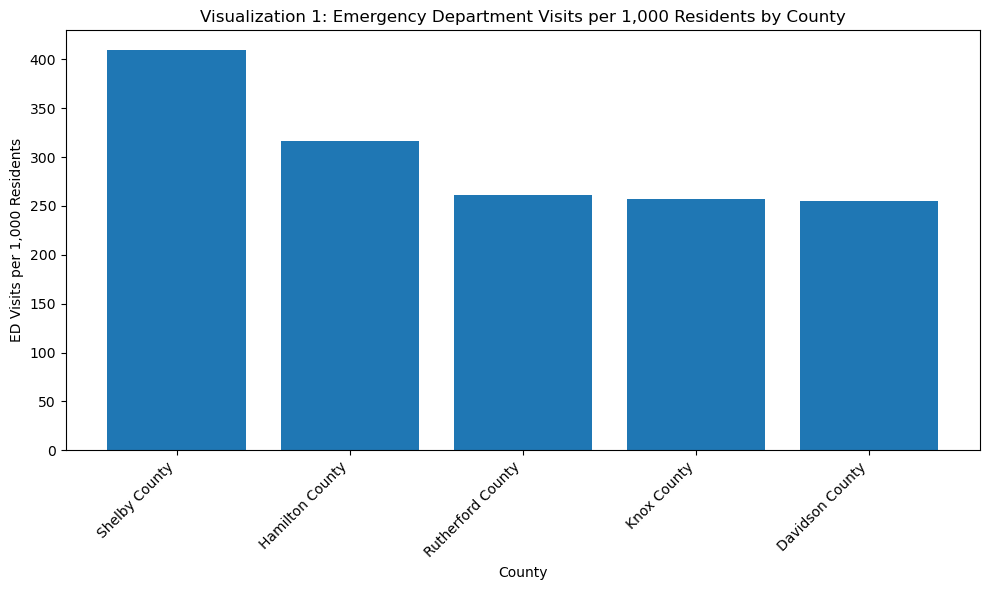

In [10]:
# Query the consolidated database table for county names and ED visit rates.
viz1_df = pd.read_sql_query(
    "SELECT county_name, ed_visits_per_1000 FROM county_healthcare_consolidated ORDER BY ed_visits_per_1000 DESC;",
    connection,
)

# Create a new figure for the emergency department visit rate chart.
plt.figure()

# Create a bar chart showing ED visits per 1,000 residents by county.
plt.bar(viz1_df["county_name"], viz1_df["ed_visits_per_1000"])

# Add a chart title that clearly labels the visualization.
plt.title("Visualization 1: Emergency Department Visits per 1,000 Residents by County")

# Label the x-axis so readers know each bar represents a county.
plt.xlabel("County")

# Label the y-axis so readers know the metric is a population-adjusted rate.
plt.ylabel("ED Visits per 1,000 Residents")

# Rotate county labels so they are readable in the exported PDF.
plt.xticks(rotation=45, ha="right")

# Apply a tight layout so labels are not cut off during PDF export.
plt.tight_layout()

# Display the chart in the notebook.
plt.show()

**Key interpretation:** Shelby County has the highest ED visit rate in this prepared dataset, while Davidson, Knox, and Rutherford counties have lower and more similar ED visit rates.

### Why this visualization matters

This visualization answers a core utilization question: which counties show the highest emergency department use after population adjustment? Shelby County has the highest ED visit rate in this prepared dataset, which may justify deeper review. The chart does not prove inefficiency, but it highlights where utilization patterns may need more context.

## Visualization 2: Average Chronic Disease Burden by County

This visualization uses the CDC chronic disease source table. It compares the average chronic disease burden field created from the selected prevalence indicators.

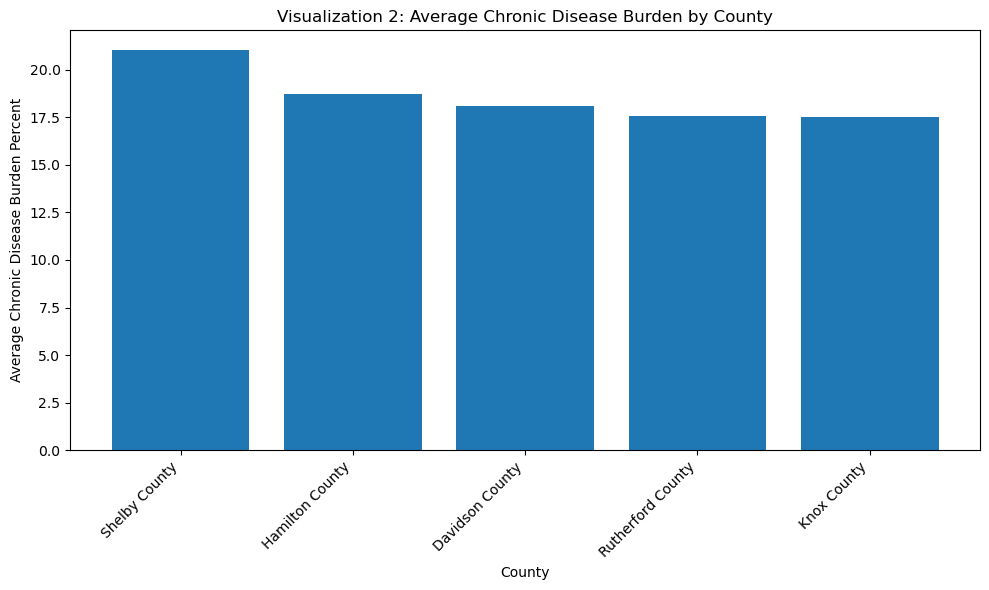

In [11]:
# Query the consolidated database table for county names and average chronic disease burden.
viz2_df = pd.read_sql_query(
    "SELECT county_name, average_chronic_disease_burden_percent FROM county_healthcare_consolidated ORDER BY average_chronic_disease_burden_percent DESC;",
    connection,
)

# Create a new figure for the chronic disease burden chart.
plt.figure()

# Create a bar chart showing average chronic disease burden by county.
plt.bar(viz2_df["county_name"], viz2_df["average_chronic_disease_burden_percent"])

# Add a chart title that clearly labels the visualization.
plt.title("Visualization 2: Average Chronic Disease Burden by County")

# Label the x-axis so readers know each bar represents a county.
plt.xlabel("County")

# Label the y-axis so readers know the metric is a percentage summary.
plt.ylabel("Average Chronic Disease Burden Percent")

# Rotate county labels so they are readable in the exported PDF.
plt.xticks(rotation=45, ha="right")

# Apply a tight layout so labels are not cut off during PDF export.
plt.tight_layout()

# Display the chart in the notebook.
plt.show()

**Key interpretation:** Shelby County also has the highest average chronic disease burden, which gives useful context for interpreting its higher ED utilization rate.

### Why this visualization matters

This visualization provides health context for the utilization analysis. Counties with higher chronic disease burden may also experience higher demand for care. This chart helps avoid interpreting utilization in isolation because population health can influence emergency department visits and inpatient admissions.

## Visualization 3: Staffed Beds per 1,000 Residents by County

This visualization uses the hospital infrastructure source table. It compares staffed bed availability using a population-adjusted rate.

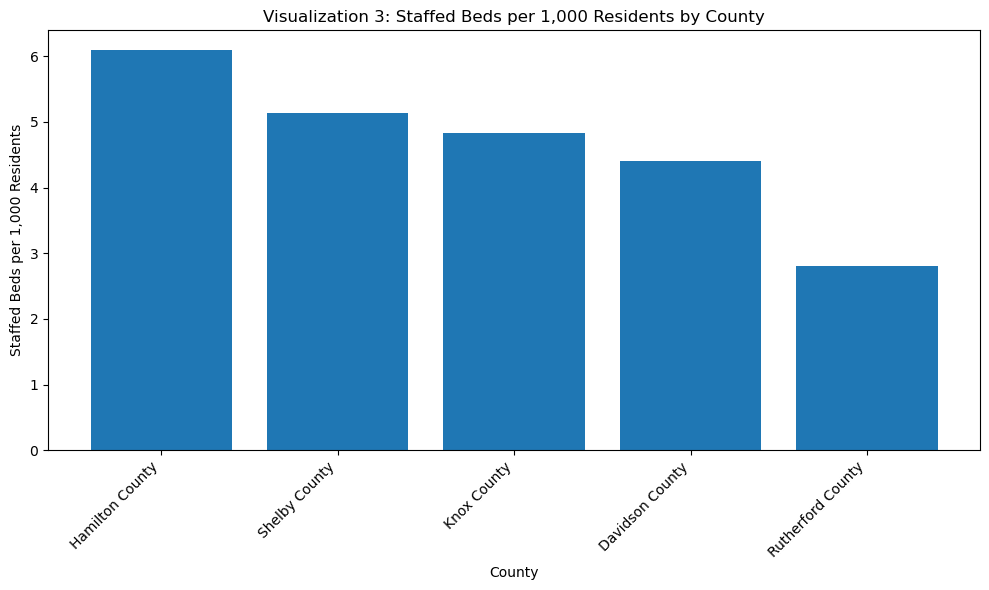

In [12]:
# Query the consolidated database table for county names and staffed bed rates.
viz3_df = pd.read_sql_query(
    "SELECT county_name, staffed_beds_per_1000 FROM county_healthcare_consolidated ORDER BY staffed_beds_per_1000 DESC;",
    connection,
)

# Create a new figure for the staffed beds chart.
plt.figure()

# Create a bar chart showing staffed beds per 1,000 residents by county.
plt.bar(viz3_df["county_name"], viz3_df["staffed_beds_per_1000"])

# Add a chart title that clearly labels the visualization.
plt.title("Visualization 3: Staffed Beds per 1,000 Residents by County")

# Label the x-axis so readers know each bar represents a county.
plt.xlabel("County")

# Label the y-axis so readers know the metric is a population-adjusted hospital capacity rate.
plt.ylabel("Staffed Beds per 1,000 Residents")

# Rotate county labels so they are readable in the exported PDF.
plt.xticks(rotation=45, ha="right")

# Apply a tight layout so labels are not cut off during PDF export.
plt.tight_layout()

# Display the chart in the notebook.
plt.show()

**Key interpretation:** Hamilton County has the highest staffed bed rate, while Rutherford County has the lowest staffed bed rate in the prepared dataset.

### Why this visualization matters

This visualization adds infrastructure context to the project. A county with high utilization and lower staffed bed availability may face different operational challenges than a county with high utilization and more hospital capacity. This chart helps connect hospital characteristics to county-level utilization patterns.

## Visualization 4: Chronic Disease Burden Compared with ED Visit Rate

This visualization uses data from more than one source because it combines the CDC chronic disease table with the utilization table through the consolidated SQL join. It compares average chronic disease burden with emergency department visit rates.

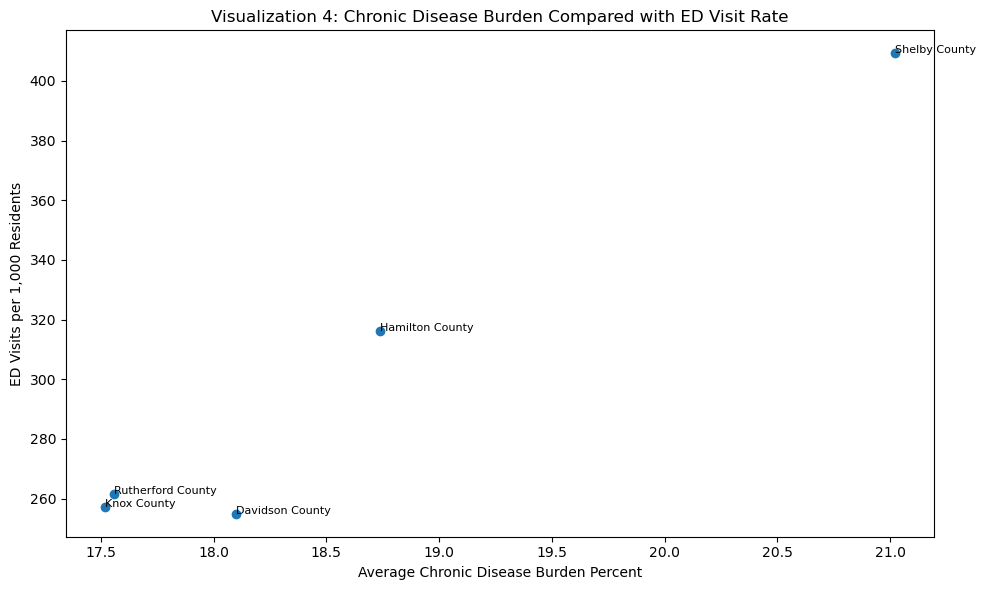

In [13]:
# Query the joined table for county names, chronic disease burden, and ED visit rates.
viz4_df = pd.read_sql_query(
    """
    SELECT county_name, average_chronic_disease_burden_percent, ed_visits_per_1000
    FROM county_healthcare_consolidated
    ORDER BY average_chronic_disease_burden_percent DESC;
    """,
    connection,
)

# Create a new figure for the joined-source scatter plot.
plt.figure()

# Create a scatter plot comparing chronic disease burden and ED visit rates.
plt.scatter(viz4_df["average_chronic_disease_burden_percent"], viz4_df["ed_visits_per_1000"])

# Add county labels near each scatter point so the chart is interpretable.
for _, row in viz4_df.iterrows():
    plt.annotate(row["county_name"], (row["average_chronic_disease_burden_percent"], row["ed_visits_per_1000"]), fontsize=8)

# Add a chart title that clearly labels the visualization.
plt.title("Visualization 4: Chronic Disease Burden Compared with ED Visit Rate")

# Label the x-axis as the CDC-derived chronic disease burden measure.
plt.xlabel("Average Chronic Disease Burden Percent")

# Label the y-axis as the CMS-style utilization rate measure.
plt.ylabel("ED Visits per 1,000 Residents")

# Apply a tight layout so labels are not cut off during PDF export.
plt.tight_layout()

# Display the chart in the notebook.
plt.show()

### Why this visualization matters

This visualization meets the requirement for a chart that spans multiple data sources. It connects CDC-style chronic disease context with CMS-style utilization patterns. This chart uses average_chronic_disease_burden_percent from the chronic disease table and ed_visits_per_1000 from the utilization table after both were joined through SQLite. The chart supports exploratory thinking about whether higher disease burden appears alongside higher emergency department use, while still avoiding a causal claim.

## Visualization 5: Utilization Rate by Hospital Location Classification

This visualization also uses more than one source because it combines utilization data with hospital infrastructure data from the joined SQL table. It compares average ED visit rates by hospital location classification.

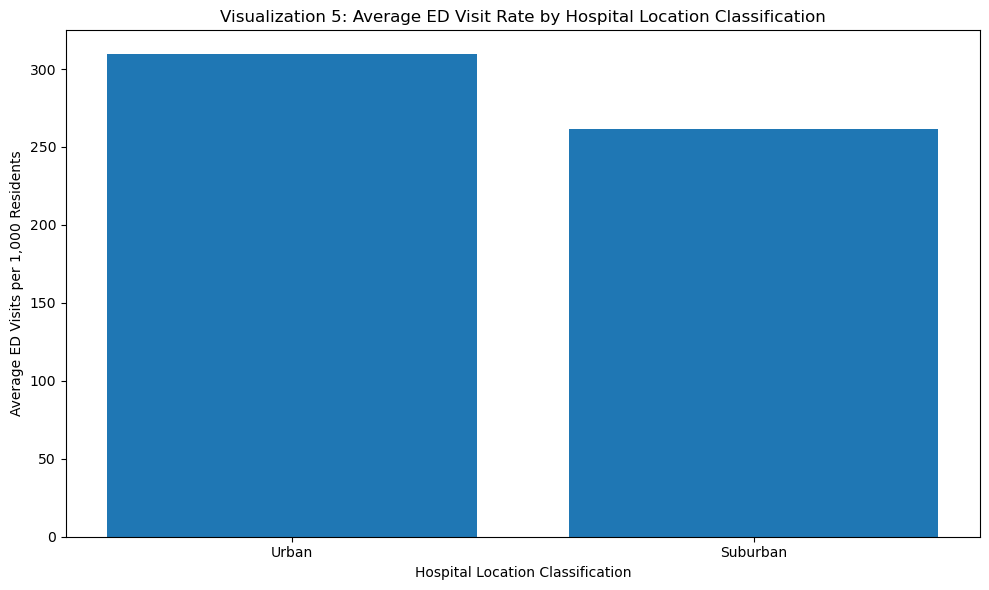

,Location,Avg ED Rate,Avg Inpatient Rate,Count
0,Urban,309.34,70.70,4
1,Suburban,261.51,51.48,1


In [14]:
# Query the joined table and summarize ED visit rates by location classification.
viz5_df = pd.read_sql_query(
    """
    SELECT
        aha_location_classification,
        AVG(ed_visits_per_1000) AS avg_ed_visits_per_1000,
        AVG(inpatient_admissions_per_1000) AS avg_inpatient_admissions_per_1000,
        COUNT(*) AS county_count
    FROM county_healthcare_consolidated
    GROUP BY aha_location_classification
    ORDER BY avg_ed_visits_per_1000 DESC;
    """,
    connection,
)

# Create a new figure for the location classification comparison chart.
plt.figure()

# Create a bar chart comparing average ED visit rates by location classification.
plt.bar(viz5_df["aha_location_classification"], viz5_df["avg_ed_visits_per_1000"])

# Add a chart title that clearly labels the visualization.
plt.title("Visualization 5: Average ED Visit Rate by Hospital Location Classification")

# Label the x-axis as the hospital location category.
plt.xlabel("Hospital Location Classification")

# Label the y-axis as the average ED visit rate.
plt.ylabel("Average ED Visits per 1,000 Residents")

# Apply a tight layout so labels are not cut off during PDF export.
plt.tight_layout()

# Display the chart in the notebook.
plt.show()

# Rename the summary columns for a cleaner human-readable display.
viz5_display = viz5_df.rename(columns={
    "aha_location_classification": "Location",
    "avg_ed_visits_per_1000": "Avg ED Rate",
    "avg_inpatient_admissions_per_1000": "Avg Inpatient Rate",
    "county_count": "Count"
})

# Round average values so the table is easier to read in the notebook and PDF.
viz5_display[["Avg ED Rate", "Avg Inpatient Rate"]] = (
    viz5_display[["Avg ED Rate", "Avg Inpatient Rate"]].round(2)
)

# Display the cleaned summary table used to create the visualization.
display(viz5_display)

### Why this visualization matters

This visualization meets the requirement for a second chart that spans multiple data sources. It connects hospital infrastructure classification with utilization rates. Because only one county in this small project sample is suburban, the chart should be interpreted cautiously. Its purpose is to demonstrate the joined-source analysis process and show how infrastructure fields can support utilization review.

## Final Human-Readable Dataset After All Transformations and Joins

This section prints the final consolidated dataset after the three cleaned datasets have been stored in SQLite, joined with SQL, and prepared for review. The table below is the final human-readable dataset required for the milestone. It represents the completed database merge after all three source tables were loaded into SQLite and joined by county FIPS. 

In [15]:
# Query the final consolidated table in a readable county order.
final_dataset = pd.read_sql_query(
    """
    SELECT
        county_fips,
        state_abbr,
        county_name,
        population,
        cms_ed_visits,
        cms_inpatient_admissions,
        ed_visits_per_1000,
        inpatient_admissions_per_1000,
        diabetes_percent,
        obesity_percent,
        high_blood_pressure_percent,
        coronary_heart_disease_percent,
        stroke_percent,
        average_chronic_disease_burden_percent,
        chronic_disease_burden_category,
        aha_hospital_count,
        aha_staffed_beds,
        staffed_beds_per_1000,
        aha_ownership_type,
        aha_location_classification,
        high_utilization_region
    FROM county_healthcare_consolidated
    ORDER BY high_utilization_region DESC, county_name ASC;
    """,
    connection,
)

# Print the final dataset shape so the notebook documents the final output size.
print("Final human-readable consolidated dataset shape:", final_dataset.shape)

# Display the final human-readable dataset after all transformations and joins.
display(final_dataset)

# Export the final human-readable dataset to CSV for optional review outside the notebook.
final_dataset.to_csv("shelia_howard_dsc540_final_consolidated_dataset.csv", index=False)

Final human-readable consolidated dataset shape: (5, 21)


,county_fips,state_abbr,county_name,population,cms_ed_visits,cms_inpatient_admissions,ed_visits_per_1000,inpatient_admissions_per_1000,diabetes_percent,obesity_percent,high_blood_pressure_percent,coronary_heart_disease_percent,stroke_percent,average_chronic_disease_burden_percent,chronic_disease_burden_category,aha_hospital_count,aha_staffed_beds,staffed_beds_per_1000,aha_ownership_type,aha_location_classification,high_utilization_region
0,47065,TN,Hamilton County,374682,118450,29850,316.13,79.67,13.1,33.5,37.6,6.1,3.4,18.74,Lower,10,2280,6.09,Nonprofit,Urban,Yes
1,47157,TN,Shelby County,916371,375000,68400,409.22,74.64,14.8,38.2,41.5,6.4,4.2,21.02,Moderate,14,4700,5.13,Government,Urban,Yes
2,47037,TN,Davidson County,715884,182500,41200,254.93,57.55,12.6,32.4,36.8,5.6,3.1,18.10,Lower,12,3150,4.40,Nonprofit,Urban,No
3,47093,TN,Knox County,500669,128700,35525,257.06,70.96,11.7,31.9,35.2,5.8,3.0,17.52,Lower,8,2420,4.83,Nonprofit,Urban,No
4,47149,TN,Rutherford County,367101,96000,18900,261.51,51.48,10.9,34.1,34.7,5.2,2.9,17.56,Lower,5,1030,2.81,Nonprofit,Suburban,No


### Why this final output matters

The final dataset shows the completed integration work for the term project. It includes utilization measures, chronic disease indicators, hospital infrastructure fields, rate calculations, and a high-utilization indicator in one human-readable table. This table is the final output of the database merge process and can support additional analysis beyond the five required visualizations.

## Summary and Ethical Implications (250-500 Words)

This final milestone required moving from separate cleaned datasets into a structured database workflow. The main changes made to the data included standardizing county FIPS codes, calculating population-adjusted utilization rates, calculating staffed beds per 1,000 residents, creating an average chronic disease burden field, and joining the three source tables into one consolidated dataset. The data was organized into separate SQLite tables first so each source remained traceable before the final SQL joins were performed.

The most important technical lesson was that data cleaning does not end when individual datasets look correct. The merge step creates a new set of risks because fields must align across sources. In this project, county FIPS was used as the join key because joining by county name alone could create errors when names are misspelled, abbreviated, or duplicated across states. After the SQL joins, missing values were checked to confirm that the tables connected correctly.

The legal and regulatory concerns are lower than they would be with patient-level data because this project uses public, aggregated, county-level healthcare indicators. However, healthcare data still carries ethical risk. A county labeled as high utilization could be misunderstood as inefficient or poorly managed when the actual explanation may involve chronic disease burden, access to care, poverty, hospital availability, age distribution, or referral patterns. The transformations also create risk because summary fields can simplify complex health conditions into a single category. For example, the average chronic disease burden field is useful for comparison, but it should not be treated as a diagnosis or a complete measure of community health. HIPAA concerns are limited because the project uses public, aggregated county-level data rather than patient-level protected health information, but healthcare data still requires careful interpretation.

Several assumptions were made. The project assumes that FIPS codes accurately connect the sources, that the selected chronic disease indicators are appropriate context for utilization, and that rate-based comparisons are more meaningful than raw counts alone. The data sources were selected because CMS, CDC, and hospital infrastructure sources are recognized public health and healthcare data providers. The data was acquired ethically because it is public and aggregated, not scraped from private systems or collected from individuals without consent.

To mitigate ethical concerns, findings should be presented as exploratory and descriptive, not causal. The analysis should clearly explain limitations, preserve source transparency, avoid stigmatizing counties, and recommend further review before policy or operational decisions are made.

## Conclusion

This notebook completes the final DSC540 term project milestone by demonstrating the full data preparation workflow from cleaned source tables to database storage, SQL joins, visualization, and ethical reflection. The project shows how separate healthcare datasets can be connected through a shared geographic identifier and prepared for analysis in a reproducible way.

The week’s database and visualization concepts are reflected throughout the notebook. Loading each dataset into SQLite shows why databases are useful for organizing related tables while preserving source structure. Joining the tables with SQL demonstrates how relational data can answer broader questions than any single table could answer alone. The visualizations then translate the merged data into interpretable patterns, including utilization differences, chronic disease burden, infrastructure variation, and relationships across multiple data sources.

The most important takeaway is that data preparation is not only technical cleanup. It also shapes interpretation. Choices such as selecting a join key, creating rates, building burden categories, and labeling high-utilization regions can influence how readers understand the data. For that reason, the notebook uses transparent comments, validation checks, clearly labeled charts, and an ethics discussion to keep the analysis responsible and grounded.

In [16]:
# Close the SQLite database connection because all database work is complete.
connection.close()

# Print a completion message so the final notebook output confirms that the workflow finished.
print("DSC540 final term project milestone notebook completed successfully.")

DSC540 final term project milestone notebook completed successfully.


### Why this code block matters

This final block closes the database connection and confirms that the notebook workflow completed successfully. Closing the connection is a good practice because it releases the database file after all SQL work is finished.